In [2]:
a = 100      
cost = 20   

In [3]:
# Cournot model
cournot_profit = function(g) {
  q = (a - cost) / (2 + g)
  (a - (1 + g) * q - cost) * q
}

In [4]:
# Bertrand model
bertrand_profit = function(g) {
  p = (a * (1 - g) + cost) / (2 - g)
  (p - cost) * (a - p) / (1 + g)
}

In [5]:
# Hybrid model
hybrid = function(g) {
  q1 = (a - cost) * (2 - g) / (4 - 3 * g^2)   # quantity-setter's output
  p2 = (a + cost - g * q1) / 2                # price-setter's price
  q2 = a - p2 - g * q1                        # price-setter's sales
  p1 = a * (1 - g) - q1 * (1 - g^2) + g * p2  # price the quantity-setter gets
  data.frame(g = g,
             quantity_setter_profit = (p1 - cost) * q1,
             price_setter_profit    = (p2 - cost) * q2)
}


In [6]:
g_show <- 0.5   # try other values between 0 and 0.95

# Profit table at g_show
h <- hybrid(g_show)
cat("Products moderately alike (g =", g_show, ")\n")
cat("  Both set quantity:  each earns", round(cournot_profit(g_show)), "\n")
cat("  Both set price:     each earns", round(bertrand_profit(g_show)), "\n")
cat("  Hybrid:  quantity-setter earns", round(h$quantity_setter_profit),
    "| price-setter earns", round(h$price_setter_profit), "\n\n")

Products moderately alike (g = 0.5 )
  Both set quantity:  each earns 1024 
  Both set price:     each earns 948 
  Hybrid:  quantity-setter earns 1022 | price-setter earns 947 



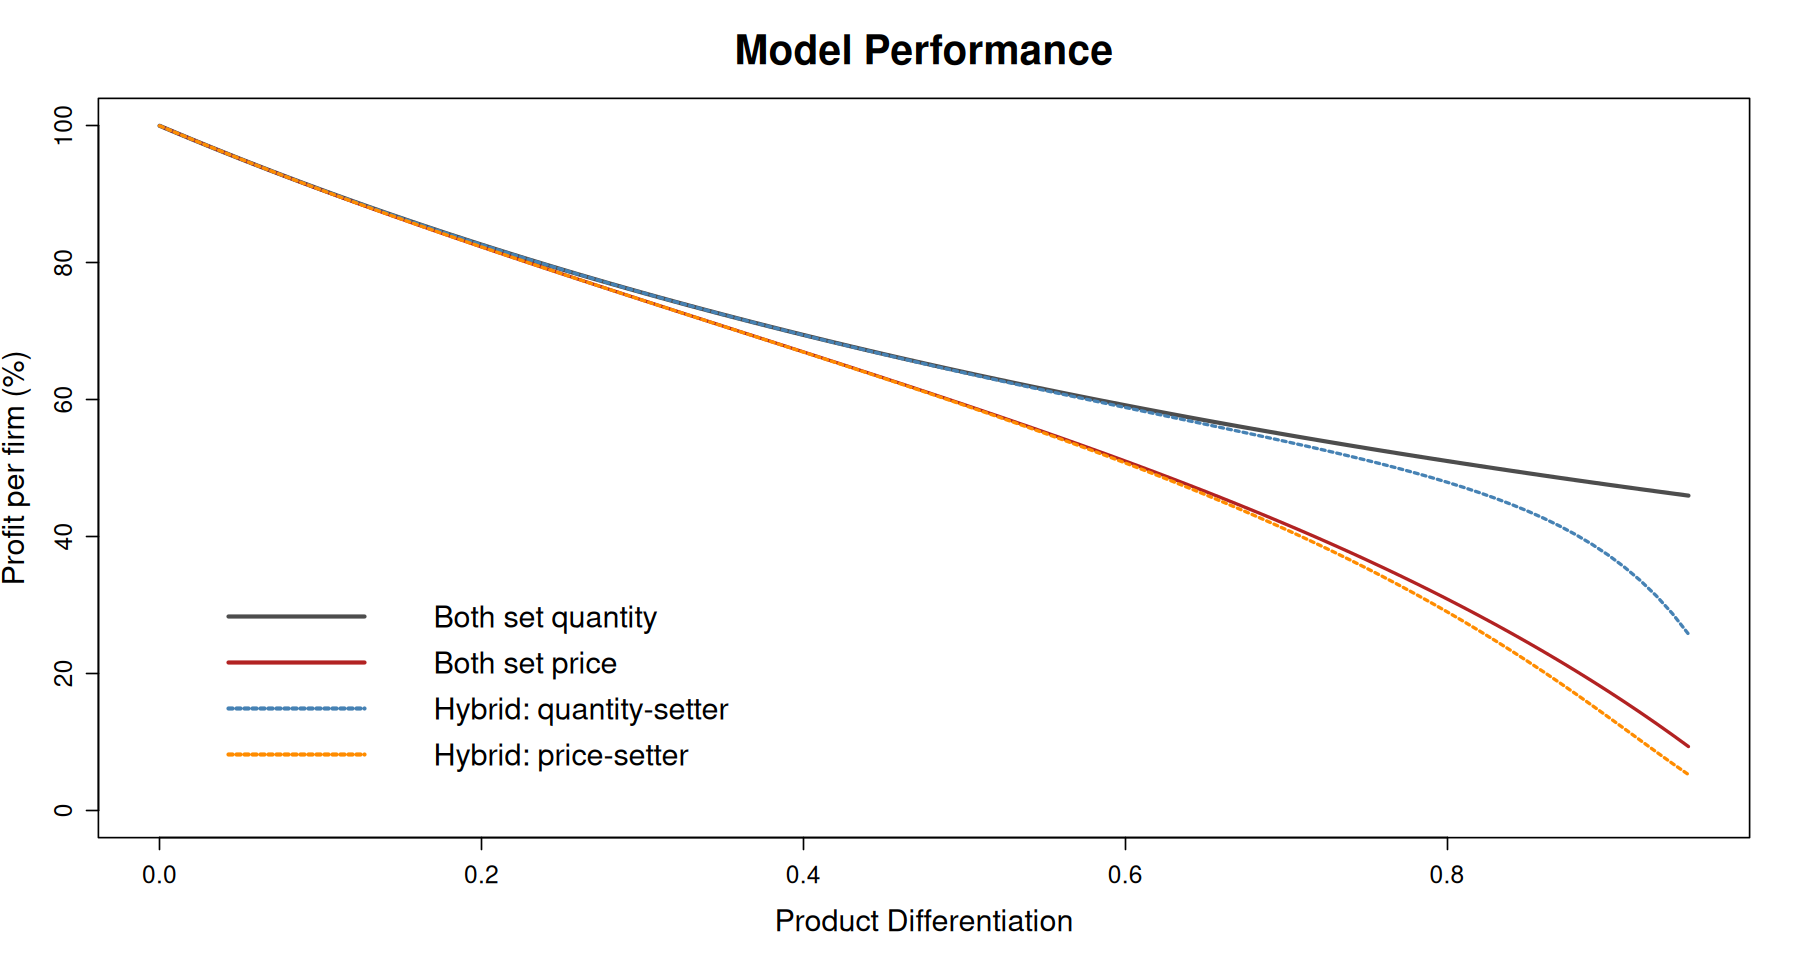

In [21]:
g = seq(0, 0.95, by = 0.01)
hy = hybrid(g)
top = cournot_profit(0)         
plot(g, 100 * cournot_profit(g) / top, type = "l", lwd = 2.5, col = "grey30",
     ylim = c(0, 100), xlab = "Product Differentiation", cex.axis = 1.2,
     ylab = "Profit per firm (%)", cex.lab = 1.5,
     main = "Model Performance", cex.main = 2)
lines(g, 100 * bertrand_profit(g) / top, lwd = 2, col = "firebrick")
lines(g, 100 * hy$quantity_setter_profit / top, lwd = 2, col = "steelblue", lty = 2)
lines(g, 100 * hy$price_setter_profit / top, lwd = 2, col = "darkorange", lty = 2)
legend(0, 35, bty = "n", lwd = 2.5, cex = 1.5,
       lty = c(1, 1, 2, 2),
       col = c("grey30", "firebrick", "steelblue", "darkorange"),
       legend = c("Both set quantity", "Both set price",
                  "Hybrid: quantity-setter", "Hybrid: price-setter"))